<a href="https://colab.research.google.com/github/fdegolla/MAT-422-Francisco-Degollado/blob/main/MAT422_HW_4_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

# MAT 422 - Homework 4.2

**Name:** Francisco Degollado

## Topic
- 4.2 Graph Modeling

## 4.2 Graph Modeling

Graph modeling is a mathematical method used to represent relationships between objects. A graph consists of vertices (nodes) and edges that connect the vertices.

A graph is represented mathematically as:

$$
G=(V,E)
$$

where:

- **G** represents the graph.
- **V** represents the set of vertices.
- **E** represents the set of edges.

Graphs can be directed or undirected. In a directed graph, edges have a specific direction. In an undirected graph, connections exist in both directions.

Graph modeling can be used to analyze networks, identify important nodes, and examine relationships between connected objects.

In this assignment, we will use Python to demonstrate graph representations, adjacency matrices, eigenvector centrality, Laplacian matrices, and their mathematical properties.

Vertices: [1, 2, 3]
Edges: [(1, 2), (2, 3)]


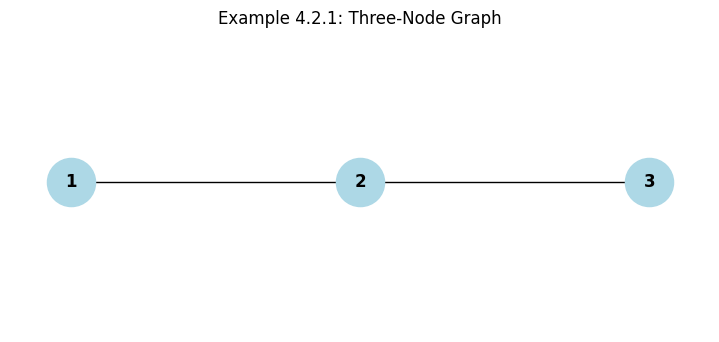

In [11]:
# Create an undirected graph
G = nx.Graph()

# Add vertices
G.add_nodes_from([1, 2, 3])

# Add edges
G.add_edges_from([(1, 2), (2, 3)])

# Display vertices and edges
print("Vertices:", list(G.nodes()))
print("Edges:", list(G.edges()))

# Visualize the graph
pos = {1: (0, 0), 2: (1, 0), 3: (2, 0)}

plt.figure(figsize=(7, 3))

nx.draw(
    G, pos,
    with_labels=True,
    node_color="lightblue",
    node_size=1200,
    edge_color="black",
    font_size=12,
    font_weight="bold"
)

plt.title("Example 4.2.1: Three-Node Graph")
plt.show()

### Adjacency Matrix

An adjacency matrix is a square matrix used to represent connections between vertices in a graph.

For an unweighted graph, the entries are defined as:

$$
A_{ij} =
\begin{cases}
1, & \text{if vertices } i \text{ and } j \text{ are connected} \\
0, & \text{otherwise}
\end{cases}
$$

For the three-node graph, the adjacency matrix is:

$$
A =
\begin{bmatrix}
0 & 1 & 0 \\
1 & 0 & 1 \\
0 & 1 & 0
\end{bmatrix}
$$

The matrix is symmetric because the graph is undirected. The diagonal entries are zero because no vertex has an edge connecting it to itself.

We will use Python to calculate the adjacency matrix and the degree of each vertex.

In [12]:
# Calculate the adjacency matrix
A = nx.to_numpy_array(G, nodelist=[1, 2, 3], dtype=int)

# Calculate vertex degrees
degrees = np.sum(A, axis=1)

# Display results
print("Adjacency Matrix:")
print(A.astype(int))

print("\nVertex Degrees:")
for i, degree in enumerate(degrees, start=1):
    print(f"Vertex {i}: Degree {degree}")

Adjacency Matrix:
[[0 1 0]
 [1 0 1]
 [0 1 0]]

Vertex Degrees:
Vertex 1: Degree 1
Vertex 2: Degree 2
Vertex 3: Degree 1


### Eigenvector Centrality

Eigenvector centrality measures the importance of a vertex based on the importance of the vertices connected to it.

Unlike degree centrality, which counts the number of connections, eigenvector centrality considers how influential the neighboring vertices are.

The mathematical relationship is:

$$
Ax=\lambda x
$$

where:

- **A** represents the adjacency matrix.
- **x** represents the eigenvector containing the centrality values.
- **λ** represents the corresponding eigenvalue.

The eigenvector associated with the largest eigenvalue is used to determine the relative importance of each vertex.

In this example, we will calculate the eigenvalues and eigenvectors of the three-node graph's adjacency matrix using Python.

In [13]:
# Calculate eigenvalues and eigenvectors
eigenvalues, eigenvectors = np.linalg.eigh(A)

# Identify the largest eigenvalue
largest_index = np.argmax(eigenvalues)
largest_eigenvalue = eigenvalues[largest_index]

# Extract the corresponding eigenvector
centrality = np.abs(eigenvectors[:, largest_index])

# Display results
print("Eigenvalues:")
print(np.round(eigenvalues, 4))

print("\nLargest Eigenvalue:")
print(round(largest_eigenvalue, 4))

print("\nEigenvector Centrality:")
for i, value in enumerate(centrality, start=1):
    print(f"Vertex {i}: {value:.4f}")

Eigenvalues:
[-1.4142 -0.      1.4142]

Largest Eigenvalue:
1.4142

Eigenvector Centrality:
Vertex 1: 0.5000
Vertex 2: 0.7071
Vertex 3: 0.5000


### Weighted Graphs and Laplacian Matrices

A weighted graph assigns a numerical weight to each edge, allowing the connections between vertices to represent different values.

The weighted adjacency matrix is defined as:

$$
A_{ij} =
\begin{cases}
w_{ij}, & \text{if vertices } i \text{ and } j \text{ are connected} \\
0, & \text{otherwise}
\end{cases}
$$

The degree matrix is a diagonal matrix containing the sum of the edge weights connected to each vertex.

$$
D_{ii}=\sum_j A_{ij}
$$

The graph Laplacian is calculated as:

$$
L=D-A
$$

The Laplacian matrix describes the structure of a graph and can be used to analyze connectivity and other properties of a network.

In this example, we will create a weighted graph with four vertices and calculate its adjacency, degree, and Laplacian matrices.

In [14]:
# Create a weighted undirected graph
G_weighted = nx.Graph()

# Add weighted edges
G_weighted.add_weighted_edges_from([
    (1, 2, 2),
    (1, 3, 1),
    (2, 3, 3),
    (3, 4, 2)
])

# Calculate weighted adjacency matrix
A_weighted = nx.to_numpy_array(
    G_weighted,
    nodelist=[1, 2, 3, 4],
    weight="weight"
)

# Calculate degree matrix
D_weighted = np.diag(np.sum(A_weighted, axis=1))

# Calculate Laplacian matrix
L_weighted = D_weighted - A_weighted

# Display results
print("Weighted Adjacency Matrix:")
print(A_weighted.astype(int))

print("\nDegree Matrix:")
print(D_weighted.astype(int))

print("\nLaplacian Matrix:")
print(L_weighted.astype(int))

Weighted Adjacency Matrix:
[[0 2 1 0]
 [2 0 3 0]
 [1 3 0 2]
 [0 0 2 0]]

Degree Matrix:
[[3 0 0 0]
 [0 5 0 0]
 [0 0 6 0]
 [0 0 0 2]]

Laplacian Matrix:
[[ 3 -2 -1  0]
 [-2  5 -3  0]
 [-1 -3  6 -2]
 [ 0  0 -2  2]]


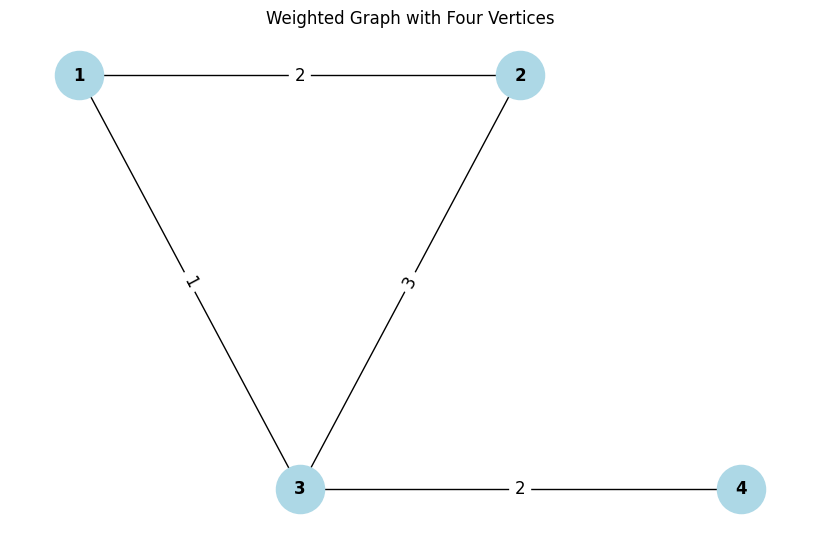

In [15]:
# Define positions for the vertices
pos_weighted = {
    1: (0, 1),
    2: (2, 1),
    3: (1, 0),
    4: (3, 0)
}

# Extract edge weights
edge_weights = nx.get_edge_attributes(G_weighted, "weight")

# Draw the weighted graph
plt.figure(figsize=(8, 5))

nx.draw(
    G_weighted,
    pos_weighted,
    with_labels=True,
    node_color="lightblue",
    node_size=1200,
    edge_color="black",
    font_size=12,
    font_weight="bold"
)

# Display edge weights
nx.draw_networkx_edge_labels(
    G_weighted,
    pos_weighted,
    edge_labels=edge_weights,
    font_size=12
)

plt.title("Weighted Graph with Four Vertices")
plt.show()

### Incidence Matrix

An incidence matrix represents the relationship between the vertices and edges of a graph.

For an oriented graph, each column represents an edge, with one entry of +1 and another entry of −1. All other entries are zero.

For a weighted graph, the incidence matrix can be scaled using the square roots of the edge weights.

The graph Laplacian can then be calculated using:

$$
L=II^T
$$

where:

- **L** represents the graph Laplacian.
- **I** represents the weighted incidence matrix.
- **Iᵀ** represents the transpose of the incidence matrix.

This relationship demonstrates how the graph Laplacian can be constructed directly from the edges of a graph.

In this example, we will calculate the weighted incidence matrix and verify that its product with its transpose equals the Laplacian matrix.

In [16]:
# Define edges and weights
edges = [
    (1, 2, 2),
    (1, 3, 1),
    (2, 3, 3),
    (3, 4, 2)
]

# Initialize the weighted incidence matrix
I = np.zeros((4, len(edges)))

# Construct the incidence matrix
for j, (u, v, weight) in enumerate(edges):
    I[u - 1, j] = np.sqrt(weight)
    I[v - 1, j] = -np.sqrt(weight)

# Calculate Laplacian using incidence matrix
L_incidence = I @ I.T

# Display results
print("Weighted Incidence Matrix:")
print(np.round(I, 4))

print("\nLaplacian from Incidence Matrix:")
print(np.round(L_incidence, 4))

# Verify the identity L = I I^T
print("\nDoes L = I I^T?")
print(np.allclose(L_weighted, L_incidence))

Weighted Incidence Matrix:
[[ 1.4142  1.      0.      0.    ]
 [-1.4142  0.      1.7321  0.    ]
 [ 0.     -1.     -1.7321  1.4142]
 [ 0.      0.      0.     -1.4142]]

Laplacian from Incidence Matrix:
[[ 3. -2. -1.  0.]
 [-2.  5. -3.  0.]
 [-1. -3.  6. -2.]
 [ 0.  0. -2.  2.]]

Does L = I I^T?
True


### Laplacian Eigenvalues and Properties

The graph Laplacian has several important mathematical properties that describe the structure and connectivity of a network.

For an undirected graph, the Laplacian is symmetric and positive semidefinite.

A matrix is positive semidefinite if:

$$
x^TLx\geq0
$$

for every vector x.

The Laplacian also satisfies:

$$
L\mathbf{1}=0
$$

where **1** represents a vector containing only ones.

Therefore, zero is always an eigenvalue of the Laplacian.

The number of zero eigenvalues equals the number of connected components in the graph.

The second-smallest eigenvalue is called the algebraic connectivity. Its corresponding eigenvector is called the Fiedler vector.

In this example, we will calculate the Laplacian eigenvalues and verify these properties using Python.

In [17]:
# Calculate Laplacian eigenvalues and eigenvectors
lap_eigenvalues, lap_eigenvectors = np.linalg.eigh(L_weighted)

# Display eigenvalues
print("Laplacian Eigenvalues:")
print(np.round(lap_eigenvalues, 4))

# Verify symmetry
print("\nIs the Laplacian symmetric?")
print(np.allclose(L_weighted, L_weighted.T))

# Verify L * 1 = 0
ones = np.ones(4)

print("\nLaplacian multiplied by ones vector:")
print(L_weighted @ ones)

# Verify positive semidefiniteness
print("\nIs the Laplacian positive semidefinite?")
print(np.all(lap_eigenvalues >= -1e-10))

# Calculate connected components
print("\nNumber of Connected Components:")
print(nx.number_connected_components(G_weighted))

# Calculate algebraic connectivity
print("\nSecond-Smallest Eigenvalue:")
print(round(lap_eigenvalues[1], 4))

# Calculate Fiedler vector
fiedler_vector = lap_eigenvectors[:, 1]

print("\nFiedler Vector:")
print(np.round(fiedler_vector, 4))

Laplacian Eigenvalues:
[-0.      1.9088  5.1648  8.9265]

Is the Laplacian symmetric?
True

Laplacian multiplied by ones vector:
[0. 0. 0. 0.]

Is the Laplacian positive semidefinite?
True

Number of Connected Components:
1

Second-Smallest Eigenvalue:
1.9088

Fiedler Vector:
[-0.5252 -0.3047  0.0362  0.7937]


## Overall Results and Interpretation

This assignment demonstrated how graphs can be used to represent and analyze networks using Python.

The three-node graph showed how vertices and edges are connected. The adjacency matrix represented these connections, and vertex 2 had the highest degree and eigenvector centrality.

The weighted graph showed how different values can be assigned to edges. The adjacency, degree, and Laplacian matrices were calculated to represent the graph.

The incidence matrix was used to verify the Laplacian matrix. The eigenvalue calculations showed that the graph was connected and that the Laplacian was symmetric and positive semidefinite.

Overall, these examples showed how graphs and matrices can be used to understand the structure and connections within a network.